# BTC 30-min — Buy & Hold (buy once, sell later)

**Rule**: buy BTC with the whole account at the **open of the first bar**, hold, and **sell at the close
of the last bar**. Two orders in total, each paying 10 bps fee + 2 bps slippage.

This is the benchmark every active strategy has to beat. The notebook shows:

1. Buy & Hold performance on every period (full / train / validation / test)
2. "Sell later" variants: buy at the start of the test period and sell after 1, 3 months or at the end
3. How the result depends on **when you buy and how long you hold** (every possible entry day)
4. Yearly / monthly returns
5. A comparison table with the other strategy notebooks (run them first so their results exist)

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)


def find_repo_root(start: Path = Path.cwd()) -> Path:
    """Walk up from the notebook folder until the folder holding all AlgoGoneCrazy-dev-* repos."""
    for p in [start, *start.parents]:
        if (p / "AlgoGoneCrazy-dev-trade-tracker").is_dir():
            return p
    raise FileNotFoundError("Could not find AlgoGoneCrazy-dev-trade-tracker above " + str(start))


REPO_ROOT = find_repo_root()
TRACKER_DIR = REPO_ROOT / "AlgoGoneCrazy-dev-trade-tracker"   # backtest engine + metrics
MODEL_DIR = REPO_ROOT / "AlgoGoneCrazy-dev-model" / "model"
RESULTS_DIR = MODEL_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)

# import the shared backtest / metrics code from the trade-tracker repo
if str(TRACKER_DIR) not in sys.path:
    sys.path.insert(0, str(TRACKER_DIR))
from src.backtest import run_backtest, buy_and_hold
from src.strategy import hold_signals
from src.metrics import compute_metrics, drawdown_series

print("repo root   :", REPO_ROOT)
print("backtest src:", TRACKER_DIR / "src")

repo root   : c:\Users\user\projects\Githubrepo
backtest src: c:\Users\user\projects\Githubrepo\AlgoGoneCrazy-dev-trade-tracker\src


## 1. Settings

In [2]:
# --- transaction costs (BTC on Binance, see AlgoGoneCrazy-dev-data/config/cost_assumptions.json)
FEE_BPS = 10.0          # 0.10% standard spot fee per order, no BNB discount
SLIPPAGE_BPS = 2.0      # half-spread + impact per order (same as trade-tracker config.py)
INITIAL_CASH = 100_000.0
ALLOW_SHORT = True

# --- chronological split, same fractions as the ML notebooks (70 / 15 / 15)
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15

BT_KW = dict(initial_cash=INITIAL_CASH, fee_bps=FEE_BPS, slippage_bps=SLIPPAGE_BPS)

SELL_AFTER_DAYS = [30, 90]                 # "sell later" variants in the test period
HOLDING_DAYS = [1, 7, 30, 90, 180, 365]    # holding periods for the entry-date analysis
TAG = "btc_buy_and_hold"

## 2. Load 30-min BTC bars

In [3]:
# First file found is used: DATA_PATH if set, then the newest BTCUSDT snapshot in the team's
# "Tsai Yi Kai - FE5209_Group_Project" OneDrive folder, then model/data/ (where the ML notebooks
# read from), then the dev-data canonical multi-asset file (filtered to BTC).
DATA_PATH = None   # set a full path here to override the search below


def shared_drive_btc_files():
    """Team OneDrive folder: .../FE5209_Group_Project/data/<yymmdd>/staging/binance_spot/BTCUSDT/.
    Newest dated snapshot first."""
    hits = []
    for base in (Path.home() / "National University of Singapore", REPO_ROOT.parent, REPO_ROOT):
        if base.is_dir():
            hits += base.glob("*FE5209_Group_Project/data/*/staging/binance_spot/BTCUSDT/"
                              "market_bars_30m_with_backfill.csv")
    return sorted(set(hits), key=lambda p: p.parts[-5], reverse=True)


DATA_CANDIDATES = ([Path(DATA_PATH)] if DATA_PATH else []) + shared_drive_btc_files() + [
    MODEL_DIR / "data" / "market_bars_30m_with_backfill.csv",
    REPO_ROOT / "AlgoGoneCrazy-dev-model" / "data" / "market_bars_30m_with_backfill.csv",
    TRACKER_DIR / "data" / "market_bars_30m_with_backfill.csv",
    REPO_ROOT / "AlgoGoneCrazy-dev-data" / "data" / "canonical" / "market_bars_30m.csv",
]
SYMBOL = "BTCUSDT"


def load_btc_bars(candidates=DATA_CANDIDATES, symbol=SYMBOL) -> pd.DataFrame:
    path = next((p for p in candidates if p.exists()), None)
    if path is None:
        raise FileNotFoundError("No 30-min bar CSV found. Put it in one of:\n" +
                                "\n".join(str(p) for p in candidates))
    raw = pd.read_csv(path)
    raw.columns = [c.lower() for c in raw.columns]
    for col in ("source_symbol", "instrument_id", "symbol"):       # multi-asset file -> BTC only
        if col in raw.columns and raw[col].nunique() > 1:
            raw = raw[raw[col].astype(str).str.upper().str.contains("BTC")]
            break
    # UTC, stored tz-naive: trade-tracker's drawdown_episodes() fails on tz-aware
    # timestamps when the last drawdown is still open (NaT + tz-aware -> object dtype)
    raw.index = pd.DatetimeIndex(pd.to_datetime(raw.pop("bar_open_time_utc"), utc=True)).tz_convert(None)
    raw = raw.sort_index()
    raw = raw[~raw.index.duplicated(keep="last")]
    print("loaded:", path)
    return raw[["open", "high", "low", "close", "volume"]].astype(float)


bars = load_btc_bars()
print(bars.shape, bars.index.min(), "->", bars.index.max())
bars.tail()

loaded: C:\Users\user\National University of Singapore\Tsai Yi Kai - FE5209_Group_Project\data\260918\staging\binance_spot\BTCUSDT\market_bars_30m_with_backfill.csv
(52608, 5) 2023-09-17 00:00:00 -> 2026-09-16 23:30:00


,open,high,low,close,volume
bar_open_time_utc,,,,,
2026-09-16 21:30:00,76074.56,76099.98,75933.11,75976.00,126.43911
2026-09-16 22:00:00,75976.01,75986.01,75667.24,75758.21,306.49196
2026-09-16 22:30:00,75758.21,75820.01,75632.70,75675.88,219.03523
2026-09-16 23:00:00,75675.88,76140.62,75643.61,76076.49,236.74200
2026-09-16 23:30:00,76076.49,76276.02,76063.77,76206.01,247.73664


In [4]:
n = len(bars)
train_end, val_end = int(n * TRAIN_FRAC), int(n * (TRAIN_FRAC + VAL_FRAC))
periods = {
    "train": (bars.index[0], bars.index[train_end - 1]),
    "val": (bars.index[train_end], bars.index[val_end - 1]),
    "test": (bars.index[val_end], bars.index[-1]),
}
for k, (a, b) in periods.items():
    print(f"{k:5s}: {a} -> {b}")


def sl(obj, period):
    """Slice a Series/DataFrame to one period (indicators are computed on the full history
    first, so each period starts with warmed-up signals and no look-ahead)."""
    a, b = periods[period]
    return obj.loc[a:b]

train: 2023-09-17 00:00:00 -> 2025-10-23 04:00:00
val  : 2025-10-23 04:30:00 -> 2026-04-05 13:30:00
test : 2026-04-05 14:00:00 -> 2026-09-16 23:30:00


## 3. Backtest (shared trade-tracker engine)

In [5]:
def backtest(pos: pd.Series, period: str):
    """Run the shared trade-tracker engine on one period (starts flat, closes out at the end)."""
    return run_backtest(sl(pos, period), sl(bars, period), asset="BTC", **BT_KW)


def metrics(res) -> pd.Series:
    return compute_metrics(res.equity, res.trades, res.positions, res.fills)


# the rows people actually look at first
KEY_ROWS = ["Total Return", "Annual Return", "Annual Volatility", "Sharpe Ratio", "Sortino Ratio",
            "Max Drawdown", "Calmar Ratio", "Number of Trades", "Win Rate",
            "Average Holding Period (hours)", "Profit Factor", "Exposure (time in market)",
            "Annual Return (before costs)", "Annual Cost Drag", "Total Transaction Cost"]


def bh(start=None, end=None):
    """Buy at the open of the first bar in [start, end], sell at the close of the last bar."""
    return buy_and_hold(bars.loc[start:end], asset="BTC", **BT_KW)

## 4. Performance matrix — every period

In [6]:
results = {"full": bh()}
for p, (a, b) in periods.items():
    results[p] = bh(a, b)

table = pd.DataFrame({f"Buy & Hold ({p})": metrics(res) for p, res in results.items()})
table.loc[KEY_ROWS].style.format("{:,.4f}")

,Buy & Hold (full),Buy & Hold (train),Buy & Hold (val),Buy & Hold (test)
Total Return,1.8744,3.0953,-0.3855,0.1378
Annual Return,0.4214,0.9557,-0.6609,0.3318
Annual Volatility,0.4731,0.4837,0.5000,0.3887
Sharpe Ratio,0.9799,1.6286,-1.9124,0.9317
Sortino Ratio,1.3845,2.3131,-2.6196,1.3367
Max Drawdown,-0.5376,-0.3242,-0.4717,-0.2953
Calmar Ratio,0.7839,2.9478,-1.4010,1.1237
Number of Trades,1.0000,1.0000,1.0000,1.0000
Win Rate,1.0000,1.0000,0.0000,1.0000
Average Holding Period (hours),"26,303.5000","18,412.0000","3,945.0000","3,945.5000"


In [7]:
table.style.format("{:,.4f}")

,Buy & Hold (full),Buy & Hold (train),Buy & Hold (val),Buy & Hold (test)
Total Return,1.8744,3.0953,-0.3855,0.1378
Annual Return,0.4214,0.9557,-0.6609,0.3318
Annual Volatility,0.4731,0.4837,0.5000,0.3887
Sharpe Ratio,0.9799,1.6286,-1.9124,0.9317
Sortino Ratio,1.3845,2.3131,-2.6196,1.3367
Max Drawdown,-0.5376,-0.3242,-0.4717,-0.2953
Calmar Ratio,0.7839,2.9478,-1.4010,1.1237
Drawdown Count (>= 1%),74.0000,74.0000,4.0000,11.0000
Longest Drawdown (days),345.1875,236.8333,160.2708,133.5000
Number of Trades,1.0000,1.0000,1.0000,1.0000


## 5. Sell later — test period

In [8]:
a, b = periods["test"]
sell_later = {"Buy & Hold (sell at end)": bh(a, b)}
for d in SELL_AFTER_DAYS:
    end = a + pd.Timedelta(days=d)
    pos = pd.Series(np.where(bars.index < end, 1, 0), index=bars.index)   # hold d days, then cash
    sell_later[f"Buy, sell after {d} days"] = backtest(pos, "test")

sell_table = pd.DataFrame({k: metrics(v) for k, v in sell_later.items()})
sell_table.loc[["Total Return", "Annual Return", "Sharpe Ratio", "Max Drawdown", "Exposure (time in market)",
                "Total Transaction Cost"]].style.format("{:,.4f}")

,Buy & Hold (sell at end),"Buy, sell after 30 days","Buy, sell after 90 days"
Total Return,0.1378,0.2143,-0.0658
Annual Return,0.3318,0.5391,-0.1402
Sharpe Ratio,0.9317,2.7011,-0.3309
Max Drawdown,-0.2953,-0.0558,-0.2953
Exposure (time in market),1.0000,0.1825,0.5474
Total Transaction Cost,256.7086,265.8994,232.2839


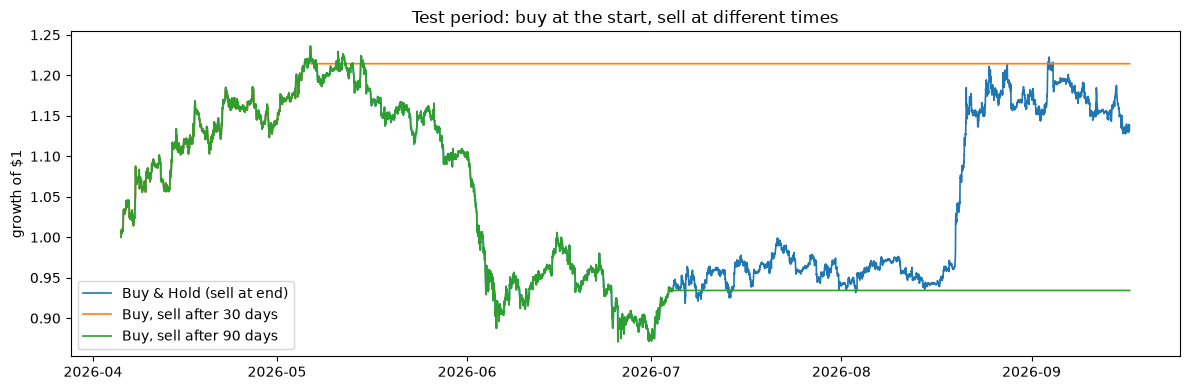

In [9]:
fig, ax = plt.subplots(figsize=(12, 4))
for k, v in sell_later.items():
    ax.plot(v.equity.index, v.equity / v.equity.iloc[0], label=k, lw=1.2)
ax.set_ylabel("growth of $1")
ax.set_title("Test period: buy at the start, sell at different times")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Does it matter when you buy and how long you hold?

For every day in the data, buy at that day's close and sell N days later (net of one round trip of
costs). This shows the spread of outcomes a buy-and-hold investor could have had.

In [10]:
daily = bars["close"].resample("1D").last().dropna()
rt_cost = 2 * (FEE_BPS + SLIPPAGE_BPS) / 1e4

rows, dists = [], {}
for d in HOLDING_DAYS:
    r = (daily.shift(-d) / daily - 1).dropna() - rt_cost
    dists[d] = r
    rows.append({"hold (days)": d, "entry dates": len(r), "P(profit)": (r > 0).mean(),
                 "mean": r.mean(), "median": r.median(), "5th pct": r.quantile(0.05),
                 "95th pct": r.quantile(0.95), "worst": r.min(), "best": r.max()})
hold_table = pd.DataFrame(rows).set_index("hold (days)")
hold_table.style.format({"entry dates": "{:,.0f}", "P(profit)": "{:.1%}", "mean": "{:.2%}",
                         "median": "{:.2%}", "5th pct": "{:.2%}", "95th pct": "{:.2%}",
                         "worst": "{:.2%}", "best": "{:.2%}"})

,entry dates,P(profit),mean,median,5th pct,95th pct,worst,best
hold (days),,,,,,,,
1,"1,095",44.6%,-0.11%,-0.18%,-3.85%,3.98%,-14.26%,11.95%
7,"1,089",52.6%,0.64%,0.31%,-9.04%,11.32%,-25.92%,30.41%
30,"1,066",57.2%,3.78%,2.15%,-19.09%,31.34%,-33.13%,58.43%
90,"1,006",55.4%,9.75%,3.71%,-24.52%,60.94%,-39.36%,83.92%
180,916,63.5%,18.51%,15.14%,-38.65%,85.34%,-46.25%,166.25%
365,731,59.0%,40.06%,38.39%,-44.54%,142.93%,-48.75%,168.02%


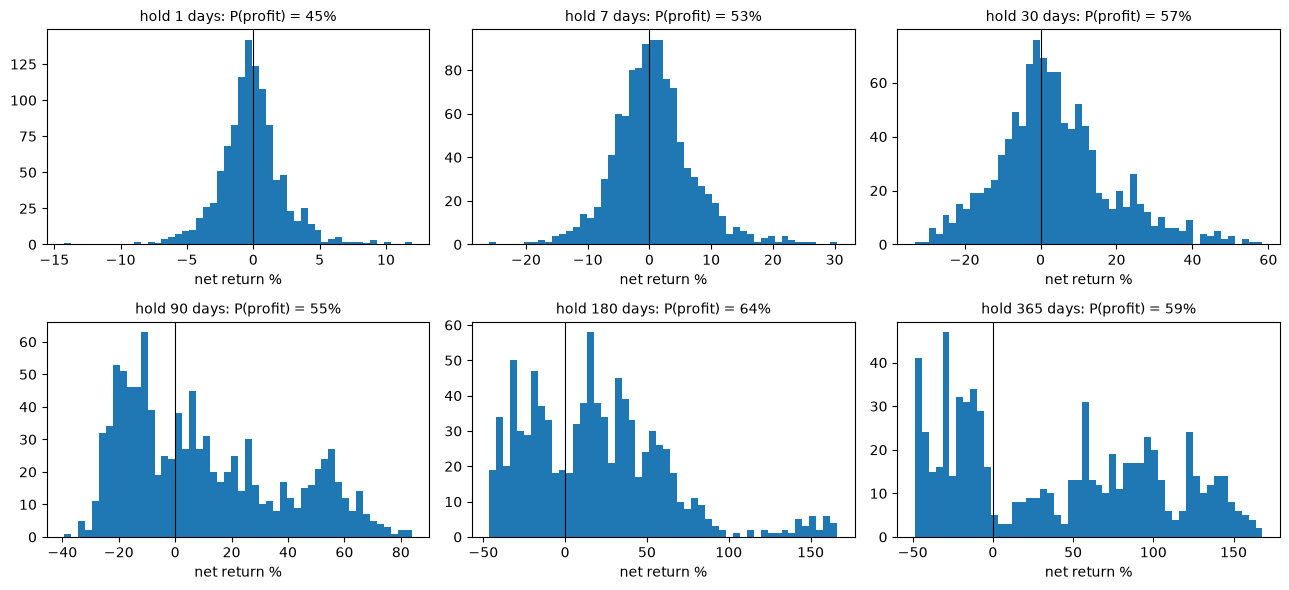

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, d in zip(axes.ravel(), HOLDING_DAYS):
    ax.hist(dists[d] * 100, bins=50)
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title(f"hold {d} days: P(profit) = {(dists[d] > 0).mean():.0%}", fontsize=10)
    ax.set_xlabel("net return %")
plt.tight_layout()
plt.show()

## 7. Equity over the full history, yearly and monthly returns

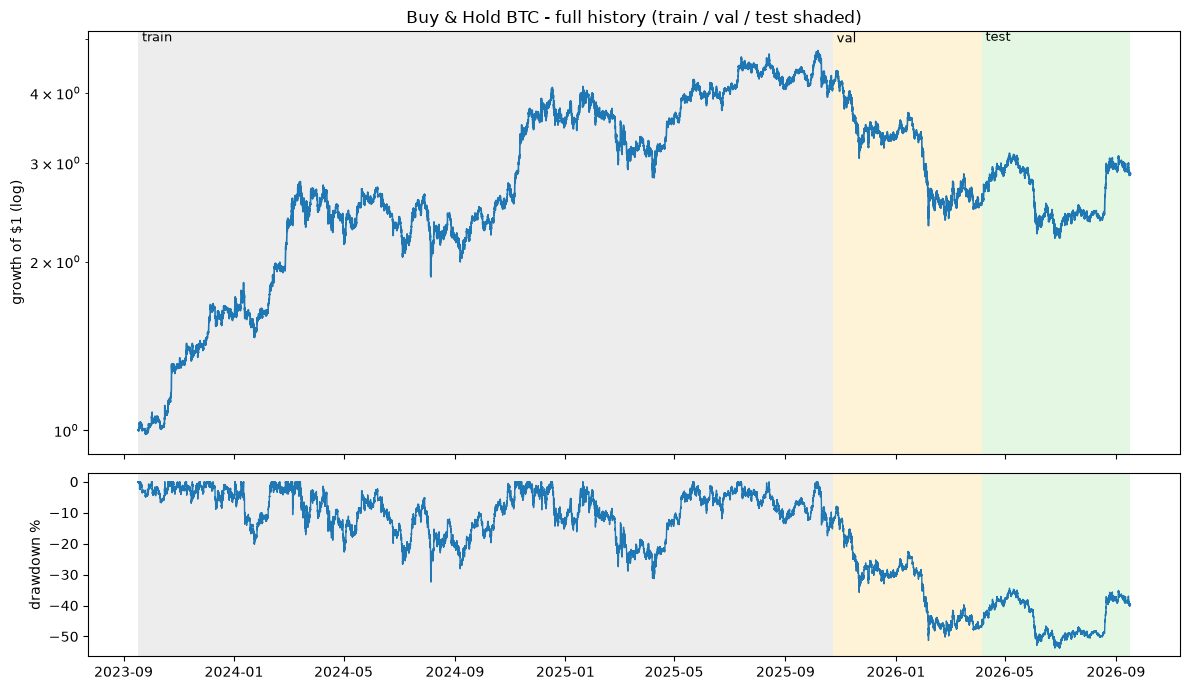

In [12]:
res = results["full"]
eq = res.equity
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
axes[0].plot(eq.index, eq / eq.iloc[0], lw=1.2)
axes[0].set_yscale("log")
axes[0].set_ylabel("growth of $1 (log)")
axes[0].set_title("Buy & Hold BTC - full history (train / val / test shaded)")
for (p, (a, b)), c in zip(periods.items(), ["#dddddd", "#ffe8b0", "#c8f0c8"]):
    for ax in axes:
        ax.axvspan(a, b, color=c, alpha=0.5, lw=0)
    axes[0].text(a, axes[0].get_ylim()[1], f" {p}", va="top", fontsize=9)
axes[1].plot(eq.index, drawdown_series(eq) * 100, lw=1)
axes[1].set_ylabel("drawdown %")
plt.tight_layout()
fig.savefig(RESULTS_DIR / f"{TAG}_equity_drawdown.png", dpi=130)
plt.show()

Yearly return (calendar years, partial first/last year):
timestamp
2023     59.6%
2024    121.4%
2025     -6.3%
2026    -13.2%


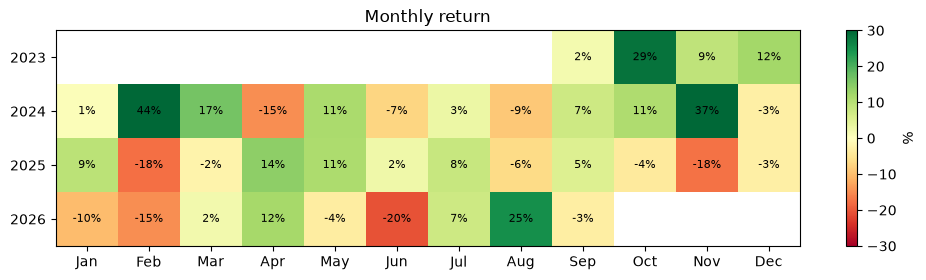

In [13]:
eq_d = eq.resample("1D").last()
yearly = eq_d.resample("YE").last().pct_change()
yearly.iloc[0] = eq_d.resample("YE").last().iloc[0] / eq.iloc[0] - 1
print("Yearly return (calendar years, partial first/last year):")
print(yearly.rename(lambda t: t.year).map("{:.1%}".format).to_string())

monthly = eq_d.resample("ME").last().pct_change()
monthly.iloc[0] = eq_d.resample("ME").last().iloc[0] / eq.iloc[0] - 1
mt = monthly.to_frame("r")
mt["year"], mt["month"] = mt.index.year, mt.index.month
heat = mt.pivot(index="year", columns="month", values="r")

fig, ax = plt.subplots(figsize=(12, 2.8))
im = ax.imshow(heat.values * 100, cmap="RdYlGn", vmin=-30, vmax=30, aspect="auto")
ax.set_xticks(range(12), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_yticks(range(len(heat.index)), heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8)
ax.set_title("Monthly return")
fig.colorbar(im, ax=ax, label="%")
plt.show()

## 8. All strategies vs Buy & Hold — test period

Collects the saved test-period tables from the other strategy notebooks in this folder
(run them first; missing ones are skipped).

In [14]:
OTHER_TAGS = ["btc_mr_slide_rule", "btc_mr_hold_to_mean", "btc_mr_best",
              "btc_mom_slide_rule", "btc_mom_best"]
parts = [metrics(results["test"]).rename("Buy & Hold")]
for t in OTHER_TAGS:
    f = RESULTS_DIR / f"{t}_metrics_test.csv"
    if f.exists():
        m = pd.read_csv(f, index_col=0)
        parts += [m[c] for c in m.columns if c != "Buy & Hold"]
    else:
        print("not found (run its notebook first):", f.name)
compare = pd.concat(parts, axis=1)
compare = compare.T.sort_values("Sharpe Ratio", ascending=False).T
compare.loc[["Annual Return", "Annual Return (before costs)", "Sharpe Ratio", "Max Drawdown",
             "Number of Trades", "Win Rate", "Exposure (time in market)"]].T.style.format(
    {"Annual Return": "{:.1%}", "Annual Return (before costs)": "{:.1%}", "Sharpe Ratio": "{:.2f}",
     "Max Drawdown": "{:.1%}", "Number of Trades": "{:,.0f}", "Win Rate": "{:.1%}",
     "Exposure (time in market)": "{:.1%}"})

,Annual Return,Annual Return (before costs),Sharpe Ratio,Max Drawdown,Number of Trades,Win Rate,Exposure (time in market)
Buy & Hold,33.2%,33.5%,0.93,-29.5%,1,100.0%,100.0%
"LONG-ONLY MR hold to mean (W=20, z=2.0/0.0)",-13.0%,74.6%,-0.57,-21.7%,148,58.8%,25.4%
"LONG-ONLY MR best (W=192, z=2.0/0.5)",-26.9%,-17.8%,-1.31,-23.5%,22,72.7%,25.8%
"MOM best (k=1, th=2.0%, H=12)",-13.8%,-9.9%,-1.84,-8.6%,8,25.0%,1.2%
"MR best (W=192, z=1.5/0.5)",-52.0%,-28.4%,-1.99,-36.0%,68,64.7%,60.7%
"LONG-ONLY MOM best (k=1, th=2.0%, H=4)",-8.9%,-6.3%,-2.00,-4.8%,5,40.0%,0.3%
"MR hold to mean (W=20, z=2.0/0.0)",-65.3%,48.9%,-3.29,-39.5%,299,53.5%,52.2%
"LONG-ONLY MOM slide rule (k=1, th=0.5%, H=1)",-68.5%,15.0%,-8.02,-42.2%,246,23.6%,3.6%
"LONG-ONLY MR slide rule (W=20, z=2.0)",-66.0%,11.9%,-9.02,-39.4%,229,24.5%,5.4%
"MR slide rule (W=20, z=2.0)",-92.4%,-8.9%,-13.55,-69.0%,449,23.4%,11.5%


## 9. Save outputs

In [15]:
table.to_csv(RESULTS_DIR / f"{TAG}_metrics_by_period.csv")
sell_table.to_csv(RESULTS_DIR / f"{TAG}_sell_later_test.csv")
hold_table.to_csv(RESULTS_DIR / f"{TAG}_holding_period_stats.csv")
compare.to_csv(RESULTS_DIR / "btc_all_strategies_test.csv")
print("saved to", RESULTS_DIR)
for f in sorted(RESULTS_DIR.glob(f"{TAG}_*")) + [RESULTS_DIR / "btc_all_strategies_test.csv"]:
    print("  ", f.name)

saved to c:\Users\user\projects\Githubrepo\AlgoGoneCrazy-dev-model\model\results
   btc_buy_and_hold_equity_drawdown.png
   btc_buy_and_hold_holding_period_stats.csv
   btc_buy_and_hold_metrics_by_period.csv
   btc_buy_and_hold_sell_later_test.csv
   btc_all_strategies_test.csv
